# Logistic regression on heart disease data

This notebook was generated using AI under general human direction. At the time of generation, the contents have not been comprehensively reviewed by a human analyst.

Converted from `ml_logistic_regression_code/logistic_regression.py`. The data come from the UCI heart disease data set (http://archive.ics.uci.edu/ml/datasets/Heart+Disease).

In [35]:
# load-packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

## Load and reformat the data

The raw file has no column names. The columns are named below, with the coding for each variable noted in comments.

In [36]:
# load-data
df = pd.read_csv("processed_cleveland_data.csv", header=None)
# df = pd.read_csv("processed_cleveland_data.csv", header=None, na_values="?")
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [37]:
# name-columns
df.columns = [
    "age",
    "sex",  # 0 = female, 1 = male
    "cp",  # chest pain
    # 1 = typical angina,
    # 2 = atypical angina,
    # 3 = non-anginal pain,
    # 4 = asymptomatic
    "trestbps",  # resting blood pressure (in mm Hg)
    "chol",  # serum cholestoral in mg/dl
    "fbs",  # fasting blood sugar if less than 120 mg/dl, 1 = TRUE, 0 = FALSE
    "restecg",  # resting electrocardiographic results
    # 1 = normal
    # 2 = having ST-T wave abnormality
    # 3 = showing probable or definite left ventricular hypertrophy
    "thalach",  # maximum heart rate achieved
    "exang",  # exercise induced angina, 1 = yes, 0 = no
    "oldpeak",  # ST depression induced by exercise relative to rest
    "slope",  # the slope of the peak exercise ST segment
    # 1 = upsloping
    # 2 = flat
    # 3 = downsloping
    "ca",  # number of major vessels (0-3) colored by fluoroscopy
    "thal",  # this is short of thalium heart scan
    # 3 = normal (no cold spots)
    # 6 = fixed defect (cold spots during rest and exercise)
    # 7 = reversible defect (when cold spots only appear during exercise)
    "hd",  # (the predicted attribute) - diagnosis of heart disease
    # 0 if less than or equal to 50% diameter narrowing
    # 1 if greater than 50% diameter narrowing
]
df.head(3)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


## Handle missing values and set variable types

The `ca` and `thal` columns contain `?` for missing values, so pandas reads them as strings. The next cell converts them to numbers and removes the rows with missing values.

In [38]:
# clean-missing
print(df.dtypes)
print(df["ca"].unique())
print(df["thal"].unique())

df = df.replace("?", np.nan)

df["ca"] = pd.to_numeric(df["ca"])
df["thal"] = pd.to_numeric(df["thal"])

df["sex"] = df["sex"].map({0: "F", 1: "M"})

df["hd"] = np.where(df["hd"] == 0, 0, 1).astype(int)

missing = df["ca"].isna() | df["thal"].isna()
print(missing.sum())
print(len(df))
print(missing.sum() / len(df))

print(len(df))
df = df[~missing].copy()
print(len(df))

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca              str
thal            str
hd            int64
dtype: object
<StringArray>
['0.0', '3.0', '2.0', '1.0', '?']
Length: 5, dtype: str
<StringArray>
['6.0', '3.0', '7.0', '?']
Length: 4, dtype: str
6
303
0.019801980198019802
303
297


## Convert factor columns to categoricals

Categories are sorted, so the first level is the reference level, as in R. The numeric factors are converted to integers first so their levels are `"0"`, `"1"`, and so on rather than `"0.0"`, `"1.0"`.

In [39]:
# categoricals
for col in ["cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    df[col] = df[col].astype(int)

for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    df[col] = df[col].astype(str).astype("category")

print(df.info())

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       297 non-null    float64 
 1   sex       297 non-null    category
 2   cp        297 non-null    category
 3   trestbps  297 non-null    float64 
 4   chol      297 non-null    float64 
 5   fbs       297 non-null    category
 6   restecg   297 non-null    category
 7   thalach   297 non-null    float64 
 8   exang     297 non-null    category
 9   oldpeak   297 non-null    float64 
 10  slope     297 non-null    category
 11  ca        297 non-null    category
 12  thal      297 non-null    category
 13  hd        297 non-null    int64   
dtypes: category(8), float64(5), int64(1)
memory usage: 18.8 KB
None


## Quality control

Each factor level should appear in both healthy and unhealthy patients. Small counts in a category can have a large effect on the odds. `restecg` is dropped after these checks.

In [40]:
# qc-crosstabs
print(pd.crosstab(df["hd"], df["sex"]))
print(pd.crosstab(df["hd"], df["cp"]))
print(pd.crosstab(df["hd"], df["fbs"]))
print(pd.crosstab(df["hd"], df["restecg"]))
df = df.drop(columns="restecg")
print(df.head())
print(pd.crosstab(df["hd"], df["exang"]))
print(pd.crosstab(df["hd"], df["slope"]))
print(pd.crosstab(df["hd"], df["ca"]))
print(pd.crosstab(df["hd"], df["thal"]))

sex   F    M
hd          
0    71   89
1    25  112
cp   1   2   3    4
hd                 
0   16  40  65   39
1    7   9  18  103
fbs    0   1
hd          
0    137  23
1    117  20
restecg   0  1   2
hd                
0        92  1  67
1        55  3  79
    age sex cp  trestbps   chol fbs  thalach exang  oldpeak slope ca thal  hd
0  63.0   M  1     145.0  233.0   1    150.0     0      2.3     3  0    6   0
1  67.0   M  4     160.0  286.0   0    108.0     1      1.5     2  3    3   1
2  67.0   M  4     120.0  229.0   0    129.0     1      2.6     2  2    7   1
3  37.0   M  3     130.0  250.0   0    187.0     0      3.5     3  0    3   0
4  41.0   F  2     130.0  204.0   0    172.0     0      1.4     1  0    3   0
exang    0   1
hd            
0      137  23
1       63  74
slope    1   2   3
hd                
0      103  48   9
1       36  89  12
ca    0   1   2   3
hd                 
0   129  21   7   3
1    45  44  31  17
thal    3   6   7
hd               
0     127   6  27
1 

## Single-predictor model: sex

Start with a simple model that uses sex to predict heart disease. The statsmodels formula interface needs a 0/1 outcome, which `hd` already is.

In [41]:
# single-variable-model
print(pd.crosstab(df["hd"], df["sex"]))

logistic = smf.glm("hd ~ sex", data=df, family=sm.families.Binomial()).fit()
print(logistic.summary())

female_log_odds = np.log(25 / 71)
print(female_log_odds)

male_log_odds_ratio = np.log((112 / 89) / (25 / 71))
print(male_log_odds_ratio)

ll_null = logistic.null_deviance / -2
ll_proposed = logistic.deviance / -2

print((ll_null - ll_proposed) / ll_null)

print(1 - chi2.cdf(2 * (ll_proposed - ll_null), df=1))
print(1 - chi2.cdf(logistic.null_deviance - logistic.deviance, df=1))

predicted_df = pd.DataFrame(
    {"probability_of_hd": logistic.fittedvalues, "sex": df["sex"]}
)

sex   F    M
hd          
0    71   89
1    25  112
                 Generalized Linear Model Regression Results                  
Dep. Variable:                     hd   No. Observations:                  297
Model:                            GLM   Df Residuals:                      295
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -193.06
Date:                Thu, 05 Nov 2026   Deviance:                       386.12
Time:                        01:26:15   Pearson chi2:                     297.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.07710
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------


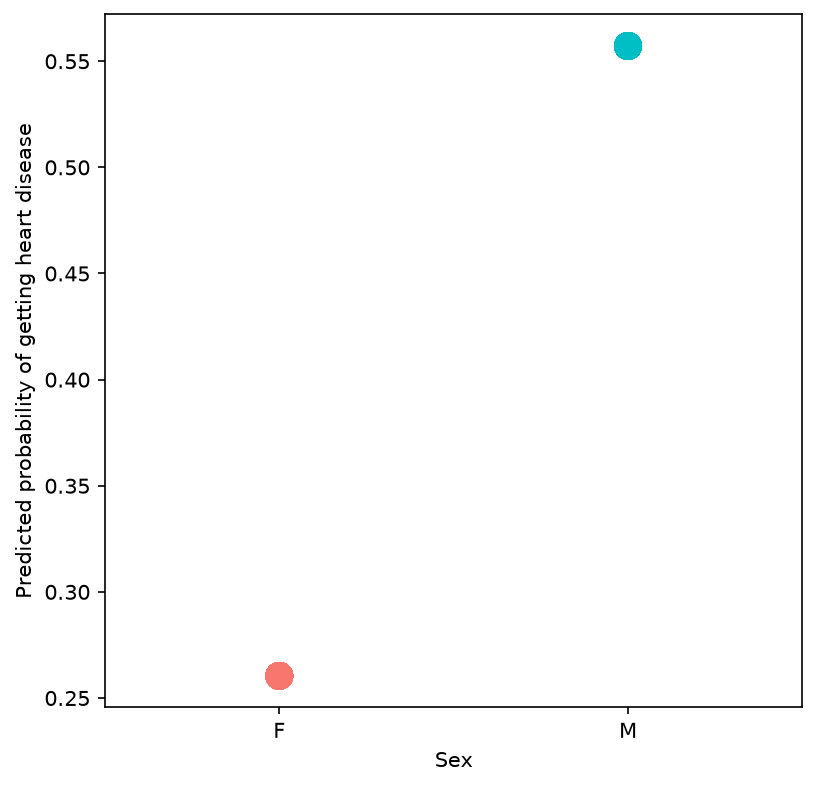

sex                 F    M
probability_of_hd         
0.260417           96    0
0.557214            0  201


In [42]:
# single-variable-plot
sex_colors = {"F": "#F8766D", "M": "#00BFC4"}

def draw_sex_plot():
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(
        x=predicted_df["sex"].map({"F": 1, "M": 2}),
        y=predicted_df["probability_of_hd"],
        c=predicted_df["sex"].map(sex_colors),
        s=150,
    )
    ax.set_xticks([1, 2], ["F", "M"])
    ax.set_xlim(0.5, 2.5)
    ax.set_xlabel("Sex")
    ax.set_ylabel("Predicted probability of getting heart disease")
    return fig


fig = draw_sex_plot()
fig.savefig("single_variable_logistic_py.pdf", transparent=True)
plt.show()

print(pd.crosstab(predicted_df["probability_of_hd"], predicted_df["sex"]))